# RMS cliff sweep: compare diversity strengths

After downloading results, **Run All** to compare **±0.10, ±0.20 and ±0.30-wave diversities**. The **Refresh and plot** cell can be rerun by itself after setup; it reloads the raw checkpoints and discovers newly downloaded runs.

The existing three-panel template is preserved: one panel per AO loop, shared linear axes, mean residual across available aberration cases, **±1 sample SD** error bars (`ddof=1`), and a dashed **y=x** reference. Colors distinguish diversity strengths consistently across the panels. Missing cases are excluded, single-case groups have no estimated SD, and nonconverged finite results are included.

Use the `phase_diversity_env` kernel. No optimization is run. See [README.md](README.md) for the command that downloads all three sweeps.


In [1]:
from pathlib import Path
import importlib
import sys

ROOT = Path.cwd().resolve()
while not ((ROOT / "utils").is_dir() and (ROOT / "optimization").is_dir()):
    if ROOT == ROOT.parent:
        raise RuntimeError("Open this notebook inside the fall_2026_lab repository.")
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display

# Show the figures inline when running in Jupyter.
shell = get_ipython()
if shell is not None:
    shell.run_line_magic("matplotlib", "inline")

from systematic_testing.rms_cliff_sweep import analyze as sweep_helpers
from systematic_testing.correction_examples import plot_pd_iteration_rms as rms_plots
importlib.reload(sweep_helpers)
importlib.reload(rms_plots)
print("Repository:", ROOT)


Repository: /Users/maxwatzky/Documents/GitHub/fall_2026_lab


## Choose the downloaded runs

All three job-ID directories live under `RESULTS_DIR`. `None` means discover the run automatically from its saved diversity magnitude. If multiple runs have the same magnitude, put the desired job ID (or absolute path) in `RUN_DIRS` rather than pooling separate sweeps. Runs not downloaded yet are reported as pending; available runs still plot.

The original baseline has no `diversity_rms` configuration field; its established default is ±0.10 waves. Explicit axis limits apply to all panels.


In [2]:
RESULTS_DIR = ROOT / "results/bouchet/rms_cliff_sweep"
RUN_DIRS = {
    0.10: "29590918",  # Original baseline; None also enables discovery.
    0.20: None,
    0.30: None,
}
OUTPUT_DIR = RESULTS_DIR / "analysis/diversity_comparison"

METRIC = "residual_rms"  # Or "estimation_rms" for estimation error before clipping.
USE_TEX = True
X_LIMITS = None  # Example: (0.0, 0.5)
Y_LIMITS = None  # Example: (0.0, 0.5)

print("Reading runs under:", RESULTS_DIR)
print("Comparison exports:", OUTPUT_DIR)


Reading runs under: /Users/maxwatzky/Documents/GitHub/fall_2026_lab/results/bouchet/rms_cliff_sweep
Comparison exports: /Users/maxwatzky/Documents/GitHub/fall_2026_lab/results/bouchet/rms_cliff_sweep/analysis/diversity_comparison


## Refresh and plot

Rerun this cell after each download. It discovers the three runs, reads `case_*/run.json` and `results.npz`, and updates the PNG/PDF comparison and CSV tables. Each point averages the available aberration cases in that sweep independently. Coverage counts make differences in completion visible.

The shared plotting helper retains the established `bmh` style, LaTeX text, 300 DPI exports, external legend, and three side-by-side AO panels. Error bars extending below zero lie outside the displayed nonnegative RMS axis. Configuration checks require the sweeps to match in every experimental setting except diversity magnitude.


Diversity ±0.10: 29590918; three-loop cases 244/400; AO fits 888/1200
Diversity ±0.20: 29606287; three-loop cases 254/400; AO fits 908/1200
Diversity ±0.30: 29606291; three-loop cases 302/400; AO fits 1004/1200
Mean ±1 sample SD; saved comparison and tables to: /Users/maxwatzky/Documents/GitHub/fall_2026_lab/results/bouchet/rms_cliff_sweep/analysis/diversity_comparison


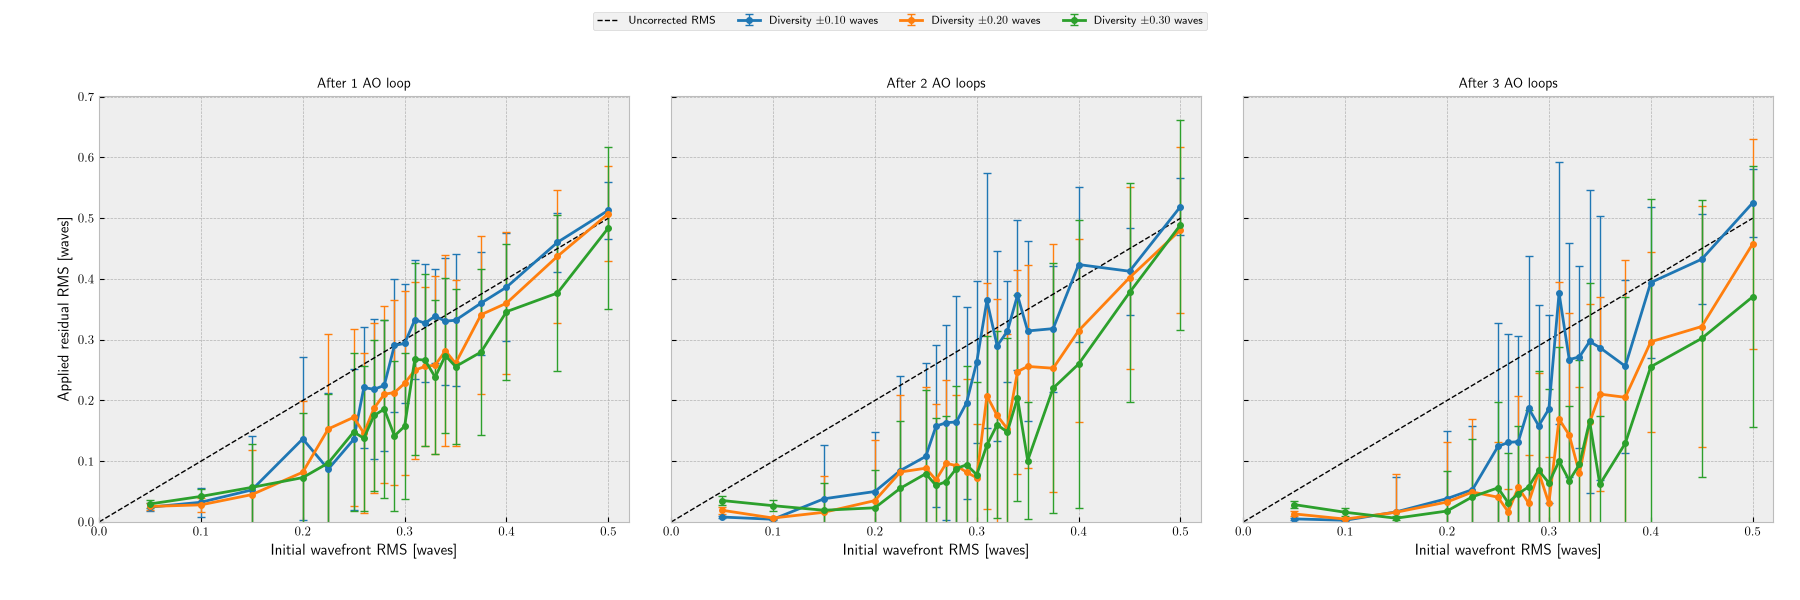

In [3]:
# Reload code and data, including runs that appeared since the last refresh.
importlib.reload(rms_plots)
importlib.reload(sweep_helpers)
candidates = sweep_helpers.discover_diversity_runs(RESULTS_DIR)
sweeps, selected_runs = {}, {}
for magnitude, chosen in sorted(RUN_DIRS.items()):
    if chosen is None:
        matches = candidates.get(magnitude, [])
        if len(matches) > 1:
            raise ValueError(f"Multiple runs at ±{magnitude:.2f} waves: {matches}. "
                             "Set the desired job ID in RUN_DIRS.")
        if not matches:
            print(f"Pending download: diversity ±{magnitude:.2f} waves")
            continue
        run = matches[0]
    else:
        run = Path(chosen)
        if not run.is_absolute():
            run = RESULTS_DIR / run
    sweeps[magnitude] = sweep_helpers.load_sweep(run)
    selected_runs[magnitude] = run
    saved = sweeps[magnitude]
    finished = int(np.all(saved["completed"], axis=-1).sum())
    print(f"Diversity ±{magnitude:.2f}: {run.name}; "
          f"three-loop cases {finished}/{saved['status'].size}; "
          f"AO fits {saved['completed'].sum()}/{saved['completed'].size}")

fig, axes = sweep_helpers.plot_diversity_comparison(sweeps, metric=METRIC, use_tex=USE_TEX)
if X_LIMITS is not None:
    axes[0].set_xlim(*X_LIMITS)
if Y_LIMITS is not None:
    axes[0].set_ylim(*Y_LIMITS)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
summary_frames, trial_frames, coverage_frames = [], [], []
for magnitude, saved in sorted(sweeps.items()):
    run = selected_runs[magnitude]
    per_run_output = run / "analysis"
    sweep_helpers.write_tables(saved, per_run_output)
    for filename, frames in (("summary.csv", summary_frames), ("trials.csv", trial_frames)):
        table = pd.read_csv(per_run_output / filename)
        table.insert(0, "diversity_rms_waves", magnitude)
        table.insert(1, "run_id", run.name)
        frames.append(table)
    counts = saved["completed"].sum(axis=1)
    coverage_frames.append(pd.DataFrame({
        "Diversity RMS [waves]": magnitude,
        "Run ID": run.name,
        "Initial RMS [waves]": saved["initial_rms"],
        "After loop 1": counts[:, 0],
        "After loop 2": counts[:, 1],
        "After loop 3": counts[:, 2],
        "Expected trials": saved["config"]["trials"],
    }))
summary = pd.concat(summary_frames, ignore_index=True)
trials = pd.concat(trial_frames, ignore_index=True)
coverage = pd.concat(coverage_frames, ignore_index=True)
summary.to_csv(OUTPUT_DIR / "comparison_summary.csv", index=False)
trials.to_csv(OUTPUT_DIR / "comparison_trials.csv", index=False)
coverage.to_csv(OUTPUT_DIR / "coverage.csv", index=False)

stem = ("residual" if METRIC == "residual_rms" else "estimation") + "_vs_initial_rms_diversity_comparison_panels"
for extension in ("png", "pdf"):
    fig.savefig(OUTPUT_DIR / f"{stem}.{extension}", dpi=300)
print("Mean ±1 sample SD; saved comparison and tables to:", OUTPUT_DIR)
display(fig)
plt.close(fig)


## Comparison with shaded 1σ and 2σ bands

The same mean curves and three AO-loop panels are shown below with **darker ±1 sample SD** and **lighter ±2 sample SD** bands instead of error bars. These describe spread across aberration cases, using `ddof=1`; they are not confidence intervals on the mean. Missing and single-case groups have no estimated band. Bands below zero lie outside the nonnegative RMS axis.

Run this cell after refreshing the data above, or use Run All.


Darker: ±1 sample SD; lighter: ±2 sample SD. Saved: /Users/maxwatzky/Documents/GitHub/fall_2026_lab/results/bouchet/rms_cliff_sweep/analysis/diversity_comparison/residual_vs_initial_rms_diversity_comparison_panels_sigma_bands.pdf


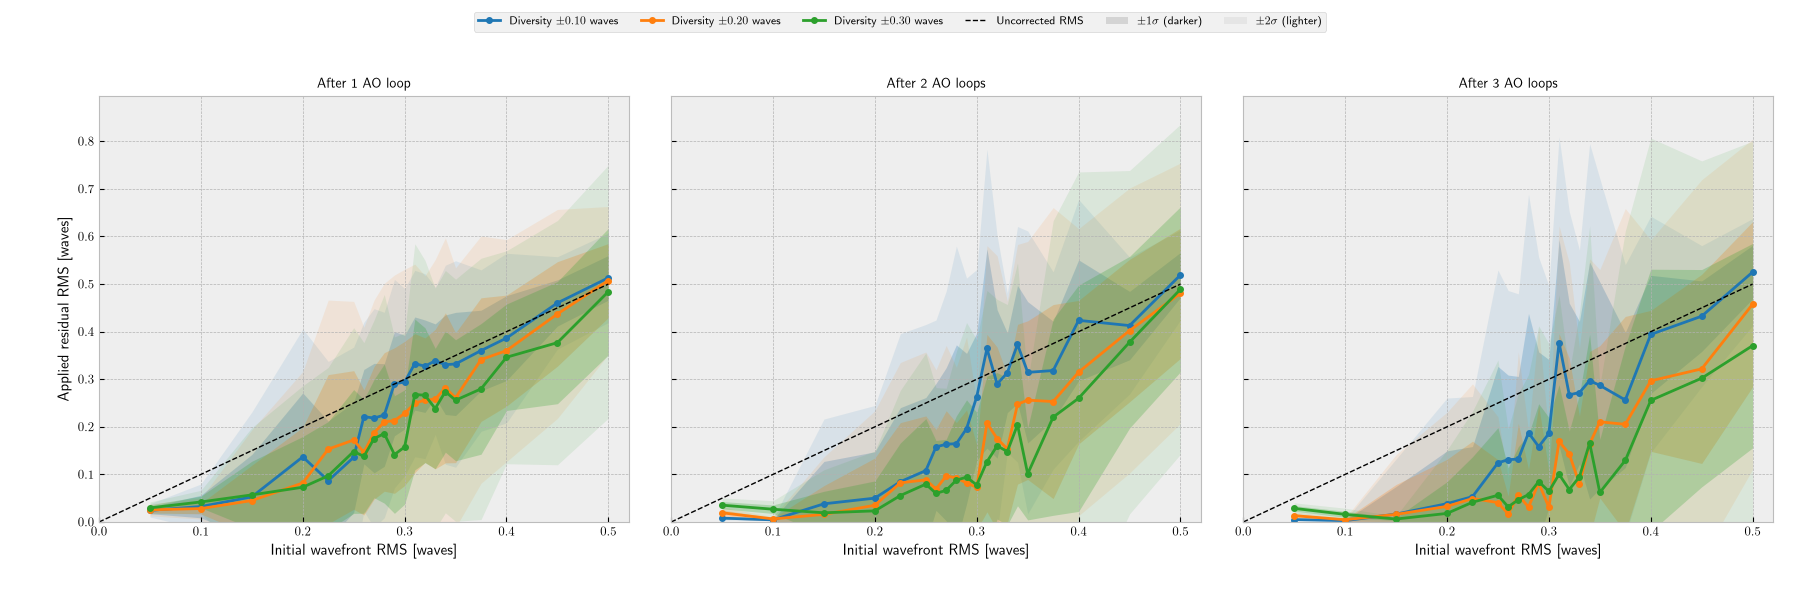

In [4]:
band_fig, band_axes = sweep_helpers.plot_diversity_comparison(
    sweeps, metric=METRIC, use_tex=USE_TEX, sigma_bands=True,
)
if X_LIMITS is not None:
    band_axes[0].set_xlim(*X_LIMITS)
if Y_LIMITS is not None:
    band_axes[0].set_ylim(*Y_LIMITS)

band_stem = stem + "_sigma_bands"
for extension in ("png", "pdf"):
    band_fig.savefig(OUTPUT_DIR / f"{band_stem}.{extension}", dpi=300)
print("Darker: ±1 sample SD; lighter: ±2 sample SD. Saved:", OUTPUT_DIR / f"{band_stem}.pdf")
display(band_fig)
plt.close(band_fig)


## Coverage and statistics

Coverage is reported separately for each sweep, RMS level and AO loop. The CSV exports retain all scheduled cases, including missing entries; the tables below show groups with saved results. Rerun the refresh cell to update both the comparison and these tables' source data.


In [5]:
count_columns = ["After loop 1", "After loop 2", "After loop 3"]
display(coverage.loc[coverage[count_columns].sum(axis=1) > 0].reset_index(drop=True))
visible = summary.loc[(summary["metric"] == METRIC) & (summary["completed_trials"] > 0)]
display(visible[[
    "diversity_rms_waves", "run_id", "initial_rms_waves", "ao_loop",
    "completed_trials", "mean_rms_waves", "std_rms_waves",
    "median_rms_waves", "fraction_at_least_initial", "converged_trials",
]].reset_index(drop=True))


,Diversity RMS [waves],Run ID,Initial RMS [waves],After loop 1,After loop 2,After loop 3,Expected trials
0,0.1,29590918,0.050,20,20,20,20
1,0.1,29590918,0.100,20,20,20,20
2,0.1,29590918,0.150,20,20,20,20
3,0.1,29590918,0.200,20,20,20,20
4,0.1,29590918,0.225,20,20,20,20
5,0.1,29590918,0.250,20,20,20,20
6,0.1,29590918,0.260,20,20,20,20
7,0.1,29590918,0.270,20,18,18,20
8,0.1,29590918,0.280,20,12,12,20
9,0.1,29590918,0.290,20,13,13,20


,diversity_rms_waves,run_id,initial_rms_waves,ao_loop,completed_trials,mean_rms_waves,std_rms_waves,median_rms_waves,fraction_at_least_initial,converged_trials
0,0.1,29590918,0.05,1,20,0.024465,0.006993,0.024197,0.000000,20
1,0.1,29590918,0.05,2,20,0.008175,0.001995,0.008915,0.000000,20
2,0.1,29590918,0.05,3,20,0.005108,0.001223,0.004782,0.000000,20
3,0.1,29590918,0.10,1,20,0.032484,0.023697,0.024570,0.050000,20
4,0.1,29590918,0.10,2,20,0.004499,0.000975,0.004376,0.000000,20
...,...,...,...,...,...,...,...,...,...,...
175,0.3,29606291,0.45,2,9,0.377845,0.180393,0.446878,0.444444,9
176,0.3,29606291,0.45,3,9,0.302216,0.228333,0.296319,0.333333,9
177,0.3,29606291,0.50,1,20,0.484184,0.132940,0.516390,0.600000,20
178,0.3,29606291,0.50,2,9,0.489199,0.173328,0.530232,0.555556,9
